# Notebook 2: Classical Models (TF-IDF + Logistic Regression / Naive Bayes / Linear SVM)

**Project:** Sentiment Analysis of E-Commerce Reviews: Classical ML vs. Transformer (DistilBERT)

**What this notebook does**

1. Loads the train / validation / test splits saved by Notebook 1.
2. Turns review text into **TF-IDF features** (fitted on the training split only).
3. Trains three classical models and tries a few settings for each:
   **Logistic Regression**, **Multinomial Naive Bayes** and **Linear SVM**.
4. Chooses the best setting of each model using the **validation** split (metric: macro-F1).
5. Saves the three final models to `models/classical/` for Phase 4 (evaluation) and Phase 5 (web app).

**The test split is NOT used here.** It is touched only once, in Phase 4, when all four models
(these three + DistilBERT) are compared. Using it now to pick settings would make the final scores look better than they really are.

**How to run:** run the cells from top to bottom (`Runtime > Run all`). It takes about a minute.

## Step 1: Set up the project folder

Same as Notebook 1: on Colab the project lives in Google Drive; on your own computer it is found automatically.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # >>> Change this line ONLY if you put the project folder somewhere else in your Drive <<<
    PROJECT_DIR = Path("/content/drive/MyDrive/ecommerce-sentiment-analysis")
else:
    # Running on your own computer: this notebook lives in <project>/notebooks/
    here = Path.cwd()
    PROJECT_DIR = here.parent if here.name == "notebooks" else here

if not (PROJECT_DIR / "src" / "config.py").exists():
    raise FileNotFoundError(
        f"Could not find the project at {PROJECT_DIR}.\n"
        "Check that the folder 'ecommerce-sentiment-analysis' (containing 'src', 'notebooks', ...) "
        "is in the place named above, or edit PROJECT_DIR."
    )

os.chdir(PROJECT_DIR)                      # work from the project root
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))   # lets us write: from src import config
print("Project folder:", PROJECT_DIR)

Project folder: C:\Users\chand\Downloads\ecommerce-sentiment-analysis-phase1\ecommerce-sentiment-analysis


## Step 2: Import libraries

> If you ever edit a file inside `src/`, use `Runtime > Restart session` and run again, otherwise Python keeps using the old version.

In [2]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import classification_report, confusion_matrix

from src import config as C
from src import data_preprocessing as dp
from src import classical_models as cm

C.ensure_dirs()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

PALETTE = {"negative": "#C44E52", "neutral": "#8C8C8C", "positive": "#55A868"}
MODEL_COLORS = {"Logistic Regression": "#4C78A8", "Naive Bayes": "#F58518", "Linear SVM": "#54A24B",
                "Majority baseline": "#BAB0AC"}

def savefig(name):
    """Save the current figure into results/figures/ (used later in the report)."""
    path = C.FIGURES_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path.relative_to(C.PROJECT_DIR))

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


## Step 3: Load the splits from Notebook 1

If this cell fails with *file not found*, run Notebook 1 first.

In [3]:
train, val, test = dp.load_splits()
for name, split in (("train", train), ("val", val), ("test", test)):
    print(f"{name:<5} {len(split):>6} reviews")

X_train_text, y_train = train[C.TEXT_COL], train[C.LABEL_ID_COL].to_numpy()
X_val_text, y_val = val[C.TEXT_COL], val[C.LABEL_ID_COL].to_numpy()
# `test` is loaded only to show its size. It is not used again in this notebook.

train  15843 reviews
val     3395 reviews
test    3395 reviews


## Step 4: Turn text into numbers (TF-IDF)

A model cannot read text, so each review becomes a long list of numbers, one per word (or word pair) in the vocabulary.

* **TF (term frequency):** how often the word appears in *this* review.
* **IDF (inverse document frequency):** words that appear in *every* review ("the", "dress") get a low weight; rarer, more informative words get a high weight.

Our settings (see `TFIDF_PARAMS` in `src/classical_models.py`):

| Setting | Value | Why |
|---|---|---|
| `ngram_range` | (1, 2) | single words **and** word pairs, so *"not good"* is its own feature |
| `min_df` | 2 | ignore terms seen in only one review (mostly typos) |
| `max_df` | 0.95 | ignore terms that appear in almost every review |
| `sublinear_tf` | True | a word repeated 5 times is not 5x as important |
| `stop_words` | None | the standard list would delete *"not"* and *"no"* (Notebook 1, Step 11) |

The vectorizer is **fitted on the training split only**: the vocabulary and IDF weights come from training reviews,
and validation reviews are only *transformed* with them. This avoids leaking information from validation into training.

In [4]:
vectorizer = cm.make_vectorizer()

start = time.time()
X_train = vectorizer.fit_transform(X_train_text)   # learn vocabulary + IDF from TRAIN only
X_val = vectorizer.transform(X_val_text)           # reuse them for VALIDATION
print(f"Fitted in {time.time() - start:.1f}s")

print("Vocabulary size (features):", f"{len(vectorizer.vocabulary_):,}")
print("Training matrix shape:", X_train.shape)
print(f"Share of non-zero values: {X_train.nnz / np.prod(X_train.shape):.4%}  (each review uses only a few words)")

Fitted in 2.1s
Vocabulary size (features): 68,334
Training matrix shape: (15843, 68334)
Share of non-zero values: 0.1287%  (each review uses only a few words)


## Step 5: A baseline to beat

Notebook 1 showed that 77% of reviews are positive. A "model" that **always** answers *positive* therefore gets
high accuracy while being useless. Its **macro-F1** (the average F1 over the three classes, each counting equally) is low,
which is why we use macro-F1, not accuracy, to choose and compare models.

In [5]:
baseline = cm.majority_baseline(y_train, y_val)
pd.DataFrame([baseline], index=["Majority baseline"]).round(3)

,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
Majority baseline,0.771,0.29,0.671,0.0,0.0,0.87


## Step 6: Train each model with several settings and score them on validation

For every model we try every combination of its settings (the grids are in `PARAM_GRIDS` in `src/classical_models.py`):

| Model | Settings tried | What they mean |
|---|---|---|
| Logistic Regression | `C` x `class_weight` | `C`: how freely the model fits the training data (higher = less regularisation). `class_weight="balanced"`: mistakes on the rare classes (negative, neutral) cost more. |
| Naive Bayes | `alpha` x `fit_prior` | `alpha`: smoothing for words never seen with a class. `fit_prior=False`: do not favour positive just because it is common. |
| Linear SVM | `C` x `class_weight` | same meaning as for Logistic Regression |

Each setting is trained on **train** and scored on **validation**. The one with the highest validation macro-F1 is kept.

In [6]:
tuning_tables, best_models, best_params = {}, {}, {}

for key, name in C.CLASSICAL_MODEL_NAMES.items():
    start = time.time()
    table, clf, params = cm.tune_model(key, X_train, y_train, X_val, y_val)
    tuning_tables[key], best_models[key], best_params[key] = table, clf, params
    print(f"{name}: tried {len(table)} settings in {time.time() - start:.1f}s; best = {params}")
    display(table.head(5).round(3))

Logistic Regression: tried 12 settings in 31.9s; best = {'C': 30.0, 'class_weight': 'balanced'}


,C,class_weight,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,30.0,balanced,0.830,0.640,0.829,0.570,0.420,0.930
1,3.0,balanced,0.816,0.633,0.822,0.561,0.415,0.923
2,0.3,balanced,0.796,0.632,0.812,0.573,0.415,0.908
3,10.0,balanced,0.824,0.632,0.825,0.559,0.409,0.928
4,1.0,balanced,0.806,0.631,0.818,0.551,0.425,0.918


Naive Bayes: tried 10 settings in 0.2s; best = {'alpha': 0.1, 'fit_prior': False}


,alpha,fit_prior,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,0.1,False,0.827,0.652,0.832,0.567,0.460,0.929
1,0.03,False,0.819,0.647,0.827,0.570,0.448,0.924
2,0.01,False,0.820,0.633,0.821,0.560,0.416,0.923
3,0.03,True,0.826,0.584,0.802,0.500,0.334,0.919
4,0.01,True,0.824,0.571,0.795,0.480,0.319,0.915


Linear SVM: tried 10 settings in 4.1s; best = {'C': 0.3, 'class_weight': 'balanced'}


,C,class_weight,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,0.3,balanced,0.835,0.638,0.830,0.572,0.410,0.933
1,0.1,balanced,0.834,0.634,0.827,0.559,0.412,0.930
2,1.0,balanced,0.833,0.631,0.827,0.570,0.391,0.932
3,3.0,balanced,0.830,0.622,0.821,0.559,0.378,0.929
4,3.0,None,0.832,0.615,0.819,0.543,0.374,0.929


### How much do the settings matter?

Each line is one value of the second setting; the x-axis is the main setting (log scale).
A flat line means the model is not sensitive to that setting; a clear peak means tuning was worth it.

Saved: results\figures\classical_tuning.png


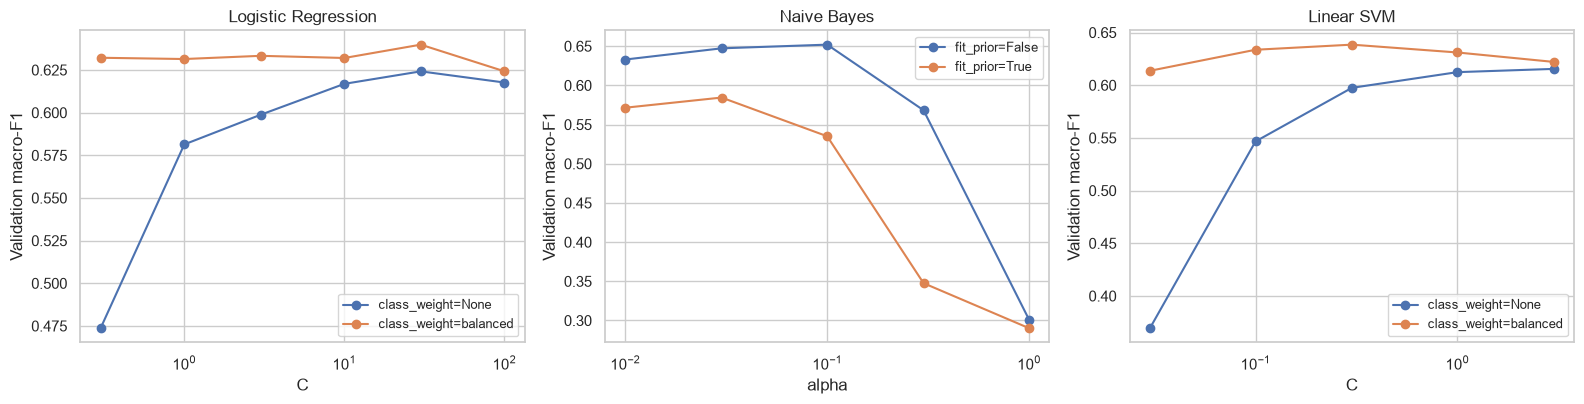

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (key, name) in zip(axes, C.CLASSICAL_MODEL_NAMES.items()):
    table = tuning_tables[key].copy()
    x_col, line_col = list(cm.PARAM_GRIDS[key])
    table[x_col] = table[x_col].astype(float)
    for value, part in table.groupby(line_col):
        part = part.sort_values(x_col)
        ax.plot(part[x_col], part[C.SELECTION_METRIC], marker="o", label=f"{line_col}={value}")
    ax.set_xscale("log")
    ax.set(title=name, xlabel=x_col, ylabel="Validation macro-F1")
    ax.legend(fontsize=9)
plt.tight_layout()
savefig("classical_tuning.png")
plt.show()

## Step 7: Compare the three tuned models (validation split)

,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
Naive Bayes,0.827,0.652,0.832,0.567,0.46,0.929
Logistic Regression,0.830,0.640,0.829,0.570,0.42,0.930
Linear SVM,0.835,0.638,0.830,0.572,0.41,0.933
Majority baseline,0.771,0.290,0.671,0.000,0.00,0.870


Saved: results\figures\classical_comparison_val.png


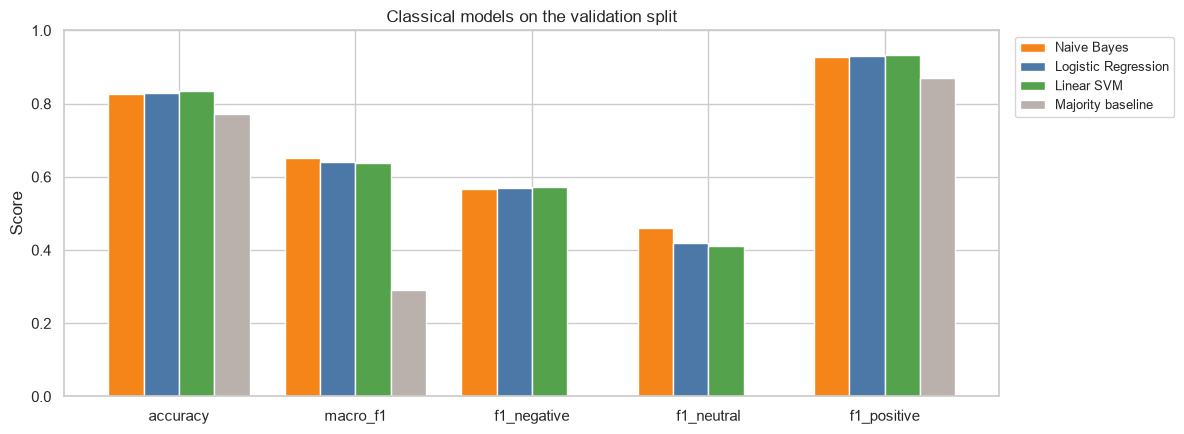

In [8]:
rows = {C.CLASSICAL_MODEL_NAMES[k]: cm.compute_metrics(y_val, best_models[k].predict(X_val)) for k in C.CLASSICAL_MODEL_NAMES}
rows["Majority baseline"] = baseline
val_results = pd.DataFrame(rows).T
val_results = val_results.sort_values(C.SELECTION_METRIC, ascending=False)
display(val_results.round(3))

metrics_to_plot = ["accuracy", "macro_f1", "f1_negative", "f1_neutral", "f1_positive"]
ax = val_results[metrics_to_plot].T.plot.bar(
    figsize=(12, 4.5), color=[MODEL_COLORS[m] for m in val_results.index], width=0.8
)
ax.set(title="Classical models on the validation split", ylabel="Score", ylim=(0, 1))
ax.set_xticklabels(metrics_to_plot, rotation=0)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
savefig("classical_comparison_val.png")
plt.show()

**How to read it:** look at the *f1_neutral* bars. Notebook 1 predicted that neutral (3-star) reviews would be the hardest
because they mix praise and complaints. The per-class F1 scores let you check that prediction with real numbers.

## Step 8: Where do the models make mistakes? (confusion matrices, validation)

Each row is the **true** class; each column is what the model **predicted**. Numbers are row percentages,
so the diagonal is the recall of each class (higher is better).

Saved: results\figures\classical_confusion_val.png


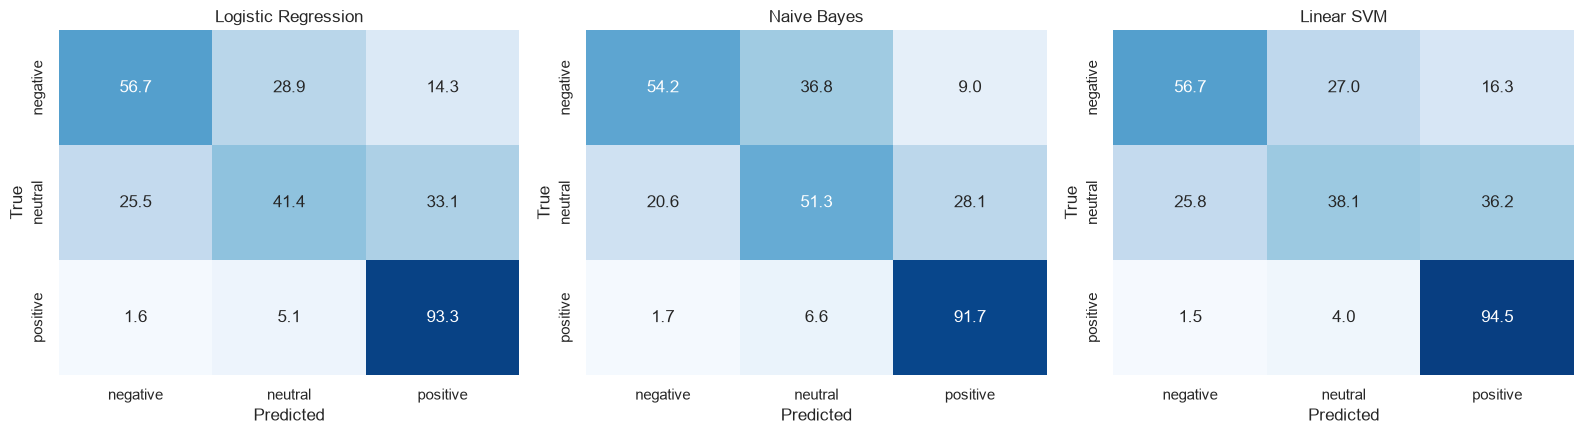

Detailed report for the best classical model (Naive Bayes):

              precision    recall  f1-score   support

    negative      0.594     0.542     0.567       356
     neutral      0.417     0.513     0.460       423
    positive      0.941     0.917     0.929      2616

    accuracy                          0.827      3395
   macro avg      0.651     0.657     0.652      3395
weighted avg      0.839     0.827     0.832      3395



In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (key, name) in zip(axes, C.CLASSICAL_MODEL_NAMES.items()):
    cmat = confusion_matrix(y_val, best_models[key].predict(X_val), normalize="true") * 100
    sns.heatmap(cmat, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                xticklabels=C.LABEL_NAMES, yticklabels=C.LABEL_NAMES)
    ax.set(title=name, xlabel="Predicted", ylabel="True")
plt.tight_layout()
savefig("classical_confusion_val.png")
plt.show()

best_key = max(C.CLASSICAL_MODEL_NAMES, key=lambda k: val_results.loc[C.CLASSICAL_MODEL_NAMES[k], C.SELECTION_METRIC])
print(f"Detailed report for the best classical model ({C.CLASSICAL_MODEL_NAMES[best_key]}):\n")
print(classification_report(y_val, best_models[best_key].predict(X_val), target_names=C.LABEL_NAMES, digits=3))

## Step 9: What has each model learned? (most important words)

Logistic Regression and Linear SVM give every word/pair a weight for each class. The words with the largest weights
are the strongest evidence for that class. This is one big advantage of classical models: they are easy to explain.
Look for word pairs containing *"not"*; they show why we kept negation words and used word pairs.

In [10]:
for key in ("logreg", "linear_svm"):
    words = cm.top_features(vectorizer, best_models[key], n=15)
    print(f"=== {C.CLASSICAL_MODEL_NAMES[key]} ===")
    display(pd.DataFrame(words))

=== Logistic Regression ===


,negative,neutral,positive
0,awful,however,love
1,cheap,not flattering,perfect
2,unflattering,color and,comfortable
3,poor,however the,great
4,disappointed,is cute,not too
5,not,unfortunately,little
6,looked like,but unfortunately,love this
7,very disappointed,just ok,comfy
8,horrible,it just,compliments
9,shapeless,returning it,perfectly


=== Linear SVM ===


,negative,neutral,positive
0,cheap,however,love
1,unflattering,however the,perfect
2,disappointed,not flattering,great
3,awful,unfortunately,comfortable
4,poor,it just,little
5,not,to love,not too
6,going back,is cute,love this
7,huge,color and,fits
8,back,cute but,perfectly
9,was,just ok,comfy


## Step 10: Save the models and the results

Each model is saved **together with its TF-IDF vectorizer** as one file, so later code can do
`model.predict(["any raw review text"])` without repeating the preprocessing.

In [11]:
for key in C.CLASSICAL_MODEL_NAMES:
    pipeline = cm.build_pipeline(vectorizer, best_models[key])
    path = cm.save_model(pipeline, key)
    print(f"Saved: {path.relative_to(C.PROJECT_DIR)}  ({path.stat().st_size / 1e6:.1f} MB)")

val_results.round(4).to_csv(C.RESULTS_DIR / "classical_val_results.csv", index_label="model")
pd.concat({C.CLASSICAL_MODEL_NAMES[k]: t for k, t in tuning_tables.items()}, names=["model", "rank"]) \
    .round(4).to_csv(C.RESULTS_DIR / "classical_tuning_all_settings.csv")

summary = {
    "selection_metric": C.SELECTION_METRIC,
    "selection_split": "val",
    "tfidf_params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in cm.TFIDF_PARAMS.items()},
    "vocabulary_size": len(vectorizer.vocabulary_),
    "param_grids": cm.PARAM_GRIDS,
    "best_params": best_params,
    "val_results": val_results.round(4).to_dict(orient="index"),
    "library_versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
summary_path = C.RESULTS_DIR / "classical_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)
print("Saved:", summary_path.relative_to(C.PROJECT_DIR))
print("Saved:", (C.RESULTS_DIR / "classical_val_results.csv").relative_to(C.PROJECT_DIR))
print("Saved:", (C.RESULTS_DIR / "classical_tuning_all_settings.csv").relative_to(C.PROJECT_DIR))

Saved: models\classical\logreg.joblib  (3.3 MB)


Saved: models\classical\naive_bayes.joblib  (4.9 MB)


Saved: models\classical\linear_svm.joblib  (3.3 MB)
Saved: results\classical_summary.json
Saved: results\classical_val_results.csv
Saved: results\classical_tuning_all_settings.csv


## Step 11: Final check (the Phase 2 checklist)

This cell reloads the models **from disk**, exactly as Phase 4 and the web app will, and checks that they
give the same validation scores and can classify brand-new sentences.

In [12]:
examples = [
    "I love this dress, it fits perfectly and the colour is beautiful.",
    "The fabric feels cheap and it fell apart after one wash. Returning it.",
    "It's okay. Nice colour but it runs small and the material is a bit thin.",
    "Not good at all.",
]

predictions = {}
for key, name in C.CLASSICAL_MODEL_NAMES.items():
    model = cm.load_model(key)
    reloaded = cm.compute_metrics(y_val, model.predict(X_val_text))
    assert abs(reloaded[C.SELECTION_METRIC] - val_results.loc[name, C.SELECTION_METRIC]) < 1e-9, f"{name}: scores changed after reload"
    assert reloaded[C.SELECTION_METRIC] > baseline[C.SELECTION_METRIC], f"{name}: does not beat the baseline"
    predictions[name] = [C.ID2LABEL[i] for i in model.predict(examples)]
    print(f"{name:<20} OK  (validation macro-F1 = {reloaded[C.SELECTION_METRIC]:.3f})")

display(pd.DataFrame(predictions, index=examples))

for name in ("classical_summary.json", "classical_val_results.csv"):
    assert (C.RESULTS_DIR / name).exists()
assert (C.FIGURES_DIR / "classical_comparison_val.png").exists()

print("\nALL PHASE 2 CHECKS PASSED")

Logistic Regression  OK  (validation macro-F1 = 0.640)


Naive Bayes          OK  (validation macro-F1 = 0.652)


Linear SVM           OK  (validation macro-F1 = 0.638)


,Logistic Regression,Naive Bayes,Linear SVM
"I love this dress, it fits perfectly and the colour is beautiful.",positive,positive,positive
The fabric feels cheap and it fell apart after one wash. Returning it.,negative,negative,negative
It's okay. Nice colour but it runs small and the material is a bit thin.,neutral,neutral,positive
Not good at all.,negative,negative,negative



ALL PHASE 2 CHECKS PASSED


## Phase 2 complete

**Files this notebook created**

* `models/classical/logreg.joblib`, `naive_bayes.joblib`, `linear_svm.joblib` (each = TF-IDF + classifier)
* `results/classical_summary.json`, `classical_val_results.csv`, `classical_tuning_all_settings.csv`
* `results/figures/classical_tuning.png`, `classical_comparison_val.png`, `classical_confusion_val.png`

**Next (Phase 3):** fine-tune DistilBERT on the same training split, choose its settings on the same validation split,
and save it. In **Phase 4** all four models are scored once on the untouched test split.

*Write down for your report:* the best settings of each model, their validation macro-F1 and per-class F1,
and which class was hardest.